# Modelos predictores no lineales: árbol y bosque

En este notebook copmparamos el desempeño predictivo del árbol de regresión y el bosque aleatorio. Usaremos los datosde salario sy empleo para Barranquilla. En ejercicios pasados observamos que MCO sobreajusta cuando la dimensionalidad crece, y mostramos cómo Lasso mejora la predicción en estas circunstancias. 

In [8]:
suppressWarnings(
pacman::p_load(xtable, dplyr, caret, rpart, RColorBrewer, rpart.plot, randomForest)
)

In [9]:
file<-"https://raw.githubusercontent.com/andvarga-eco/econometrics_ml/refs/heads/main/data/geih_24_baq.csv"
data<-read.csv(file)

In [10]:
data<-data|>filter(P6040 %in% 25:64)|>filter(P3042!=99)
data<-na.omit(data)
data<-data|>filter(P6800<=60)|>mutate(w=INGLABO/(P6800*4),lw=log(w),
                                      edad2=P6040^2, edad3=P6040^3, edad4=P6040^4)
data<-data|>mutate(P3271=factor(P3271), P3042=factor(P3042),
RAMA2D_R4=forcats::fct_lump_n(factor(RAMA2D_R4),n=40,other_level="Otras"))

In [11]:
set.seed(1234)
training <- sample(nrow(data), nrow(data) * (3 / 4), replace = FALSE)
data_train <- data[training, ]
data_test <- data[-training, ]

## Árbol de regresión


Regression tree:
rpart(formula = basic, data = data_train, minbucket = 5, cp = 0.001)

Variables actually used in tree construction:
[1] P3042     P3271     P6040     RAMA2D_R4

Root node error: 1176.4/3122 = 0.37682

n= 3122 

          CP nsplit rel error  xerror     xstd
1  0.3310906      0   1.00000 1.00053 0.037502
2  0.0821922      1   0.66891 0.66983 0.027538
3  0.0153198      2   0.58672 0.58796 0.025339
4  0.0145157      3   0.57140 0.58683 0.025442
5  0.0103253      4   0.55688 0.57431 0.024849
6  0.0081126      5   0.54656 0.57606 0.024852
7  0.0080498      6   0.53844 0.57351 0.024485
8  0.0047671      7   0.53039 0.56964 0.024347
9  0.0039436      8   0.52563 0.56969 0.024068
10 0.0038290     10   0.51774 0.56975 0.024091
11 0.0034930     11   0.51391 0.57014 0.024104
12 0.0031196     12   0.51042 0.57182 0.024085
13 0.0029722     14   0.50418 0.57430 0.024200
14 0.0029171     16   0.49823 0.57454 0.024193
15 0.0029168     17   0.49532 0.57536 0.024141
16 0.0027103     18

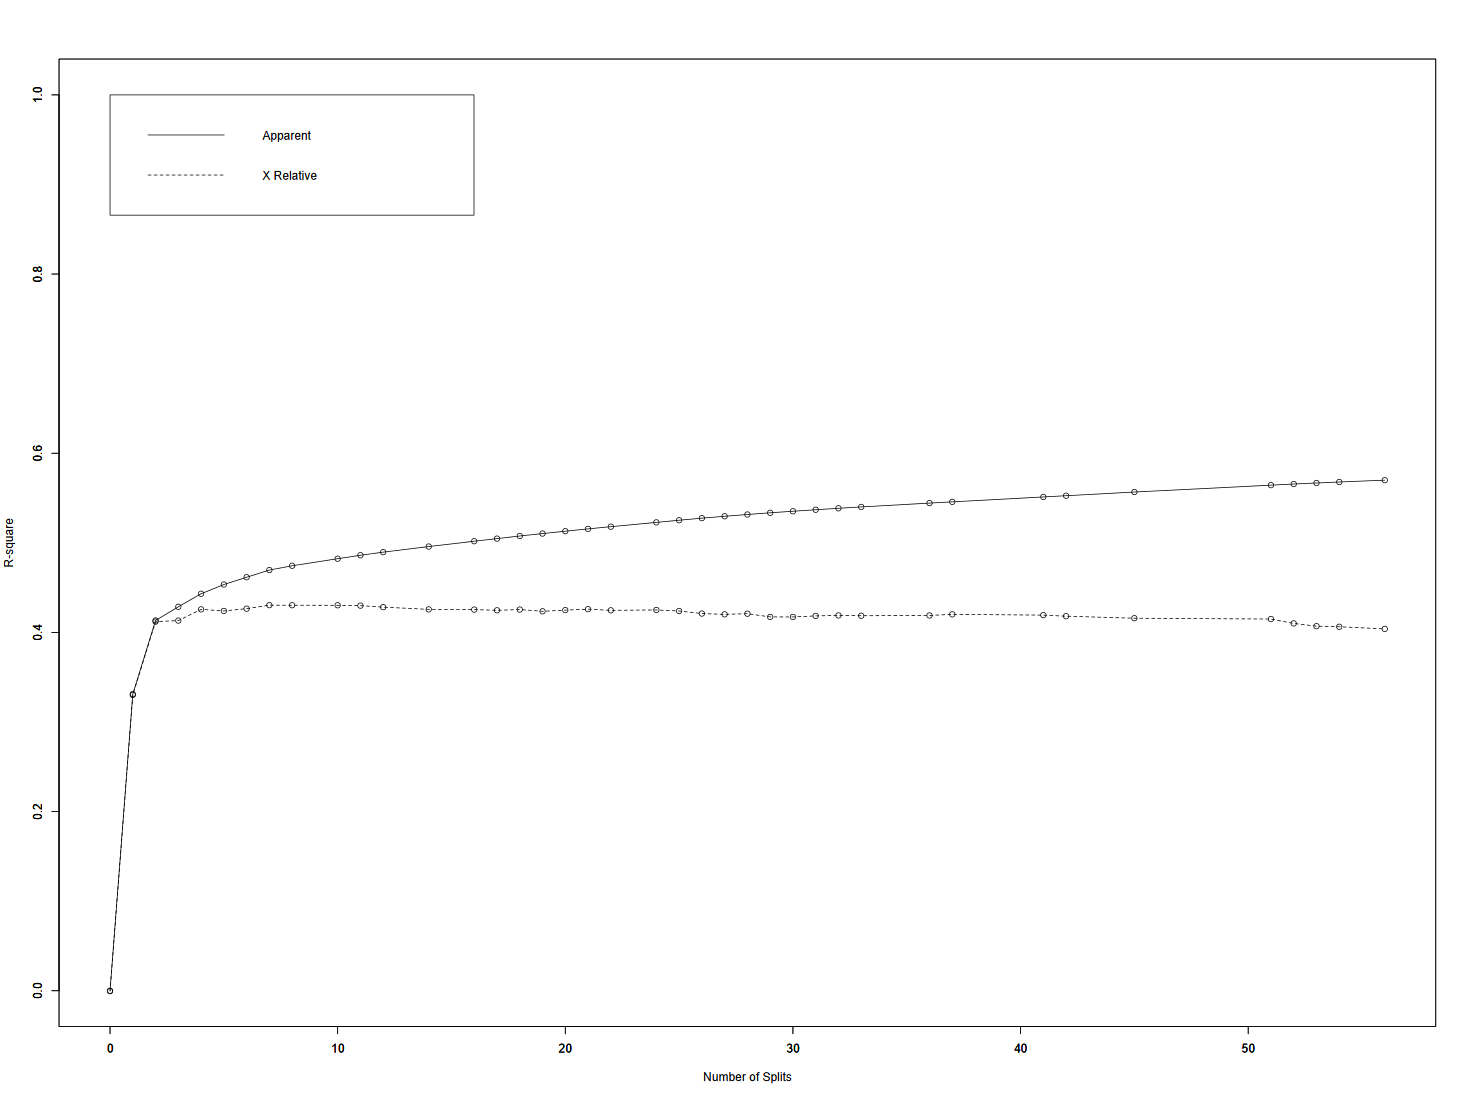

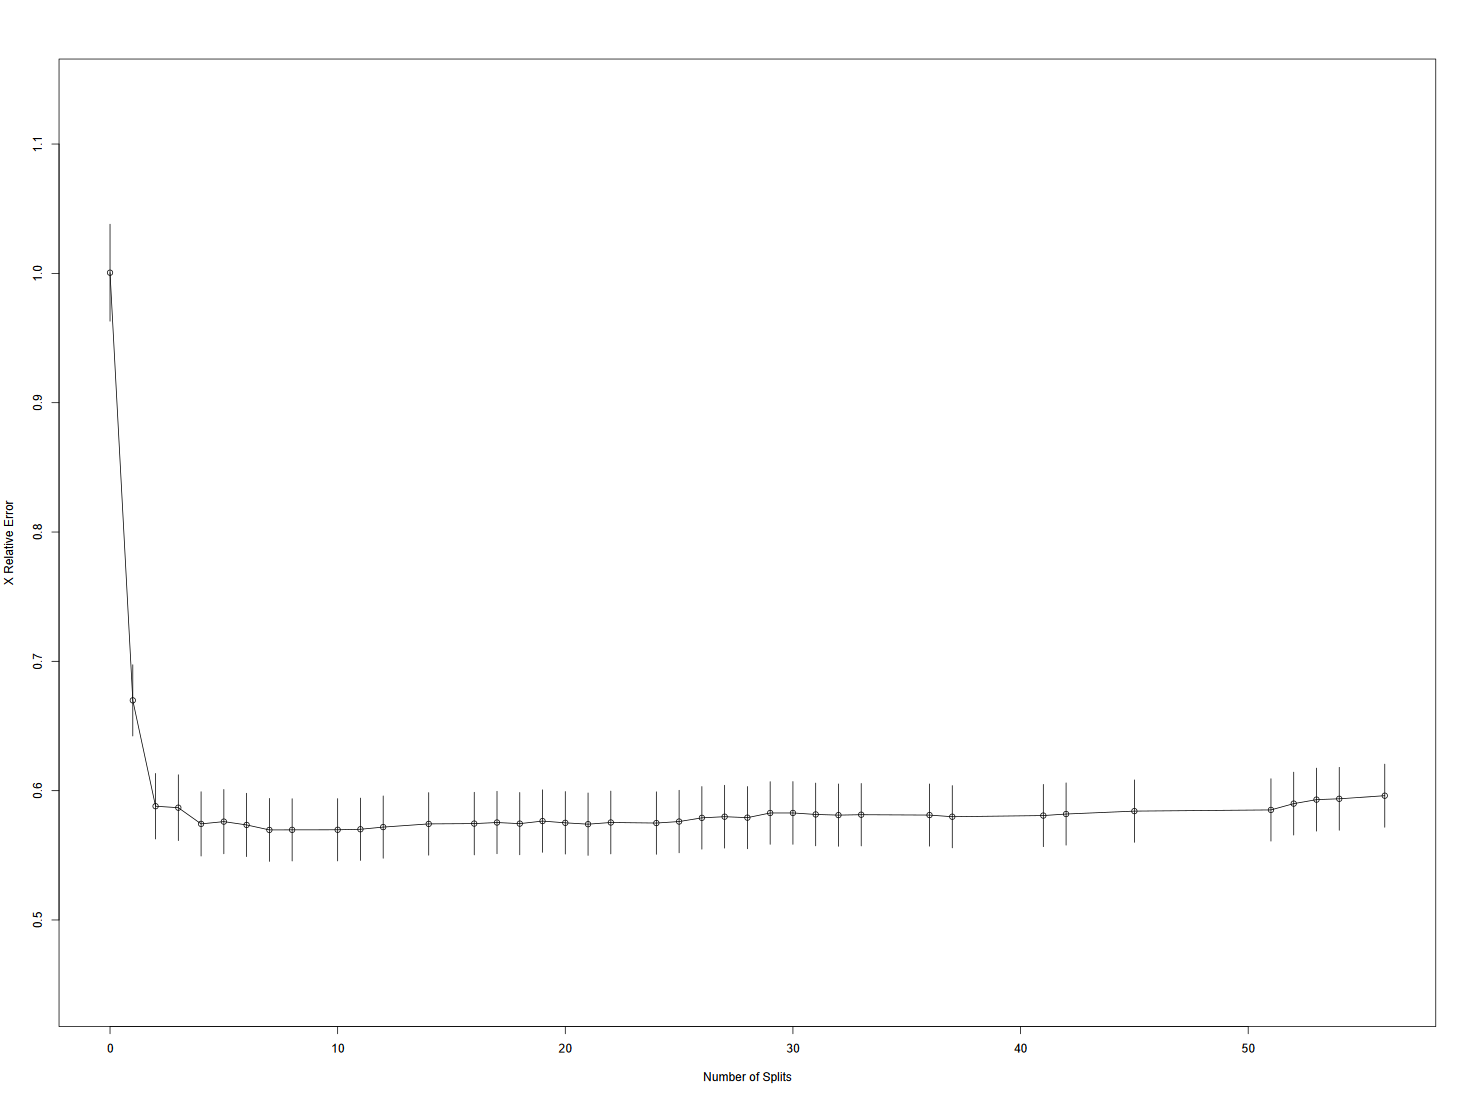

In [14]:
basic<-lw~(P3271+P6040+P3042+RAMA2D_R4)
tree.fit.basic<-rpart(basic,data=data_train,minbucket=5, cp=0.001)
printcp(tree.fit.basic)
rsq.rpart((tree.fit.basic))

In [16]:
bestcp <- tree.fit.basic$cptable[which.min(tree.fit.basic$cptable[, "xerror"]), "CP"]
bestcp

[1] 0.004767088


Regression tree:
rpart(formula = basic, data = data_train, minbucket = 5, cp = 0.001)

Variables actually used in tree construction:
[1] P3042     P6040     RAMA2D_R4

Root node error: 1176.4/3122 = 0.37682

n= 3122 

         CP nsplit rel error  xerror     xstd
1 0.3310906      0   1.00000 1.00053 0.037502
2 0.0821922      1   0.66891 0.66983 0.027538
3 0.0153198      2   0.58672 0.58796 0.025339
4 0.0145157      3   0.57140 0.58683 0.025442
5 0.0103253      4   0.55688 0.57431 0.024849
6 0.0081126      5   0.54656 0.57606 0.024852
7 0.0080498      6   0.53844 0.57351 0.024485
8 0.0047671      7   0.53039 0.56964 0.024347


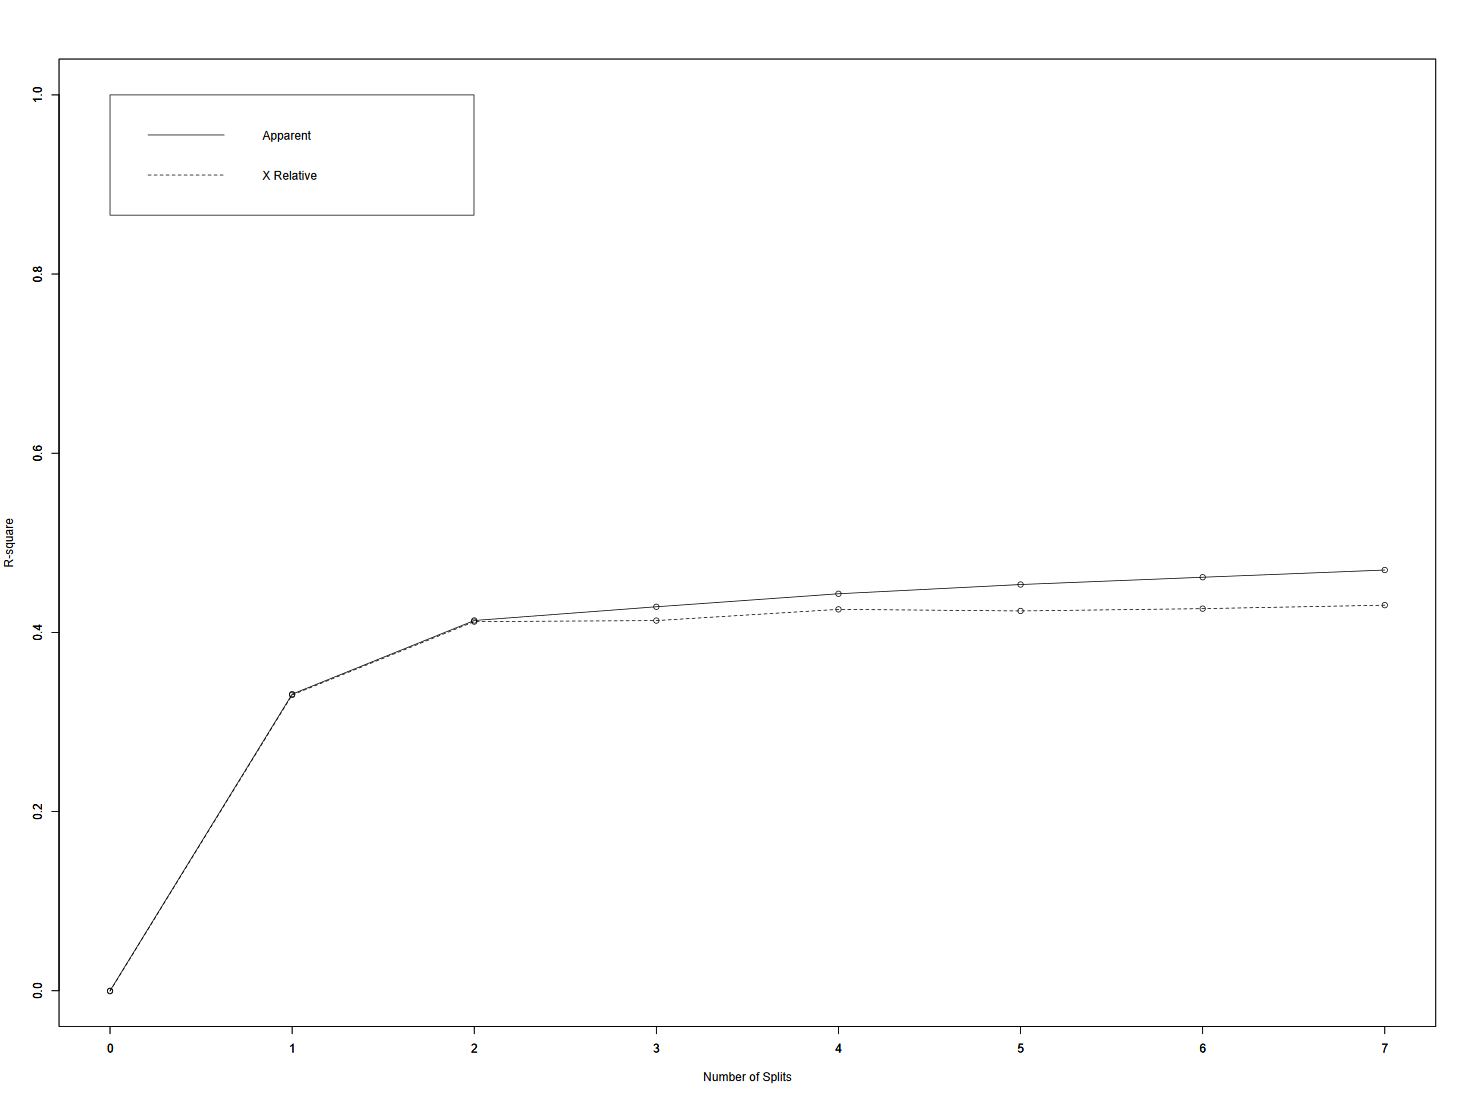

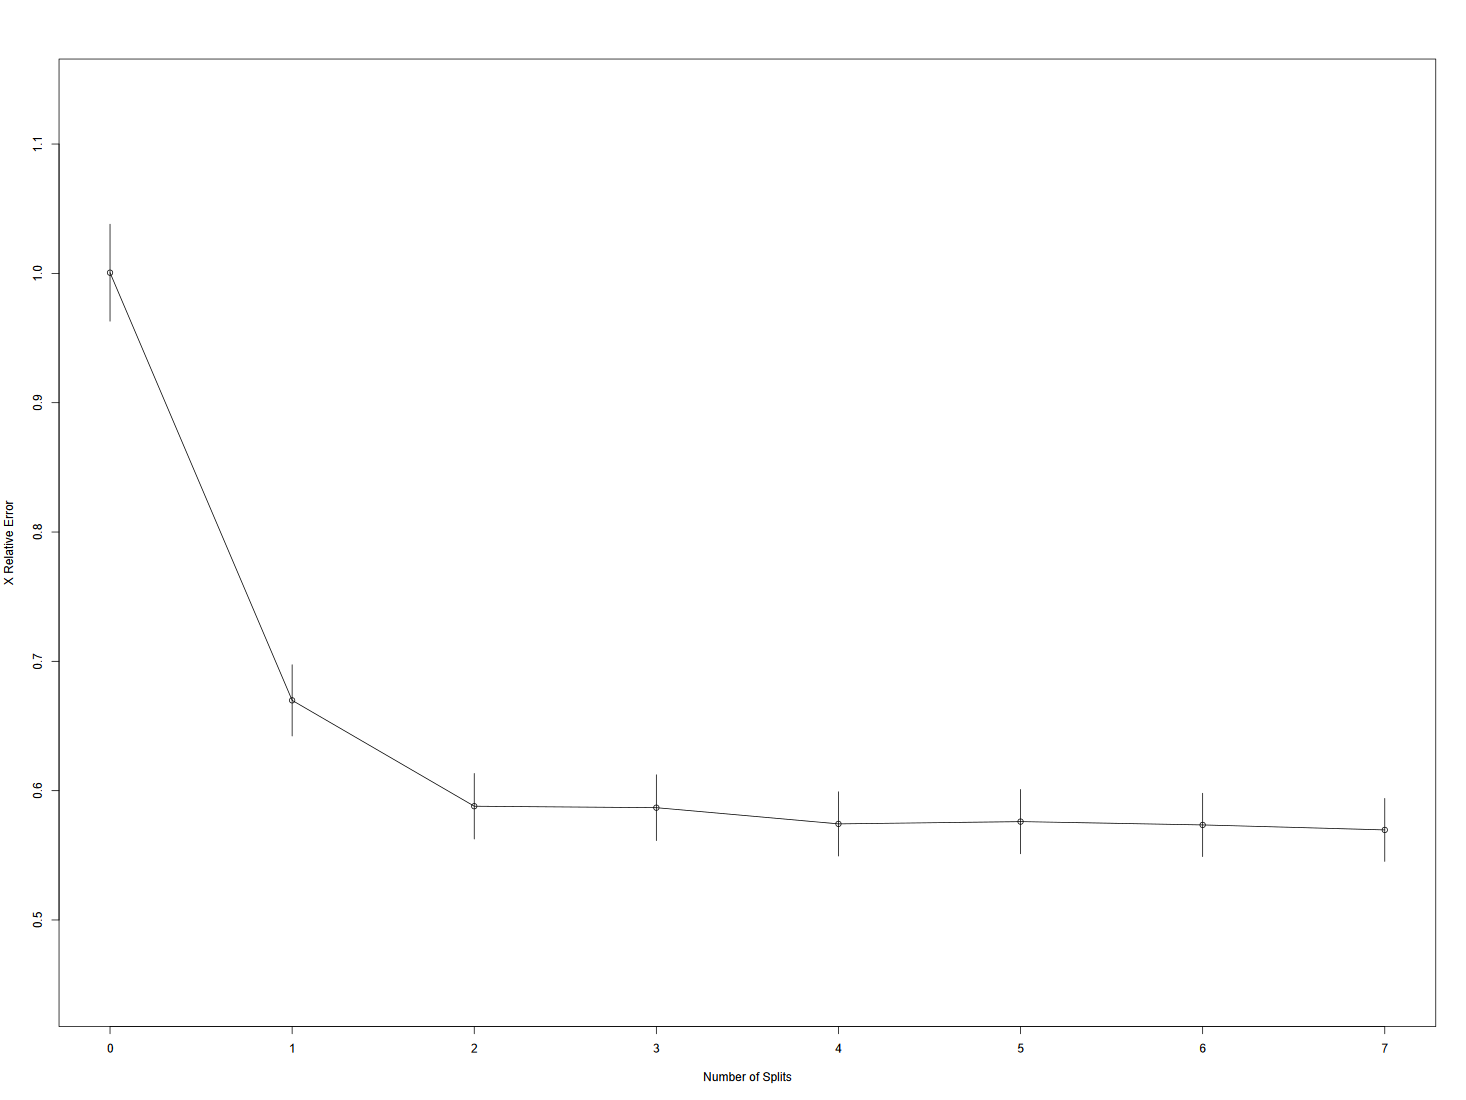

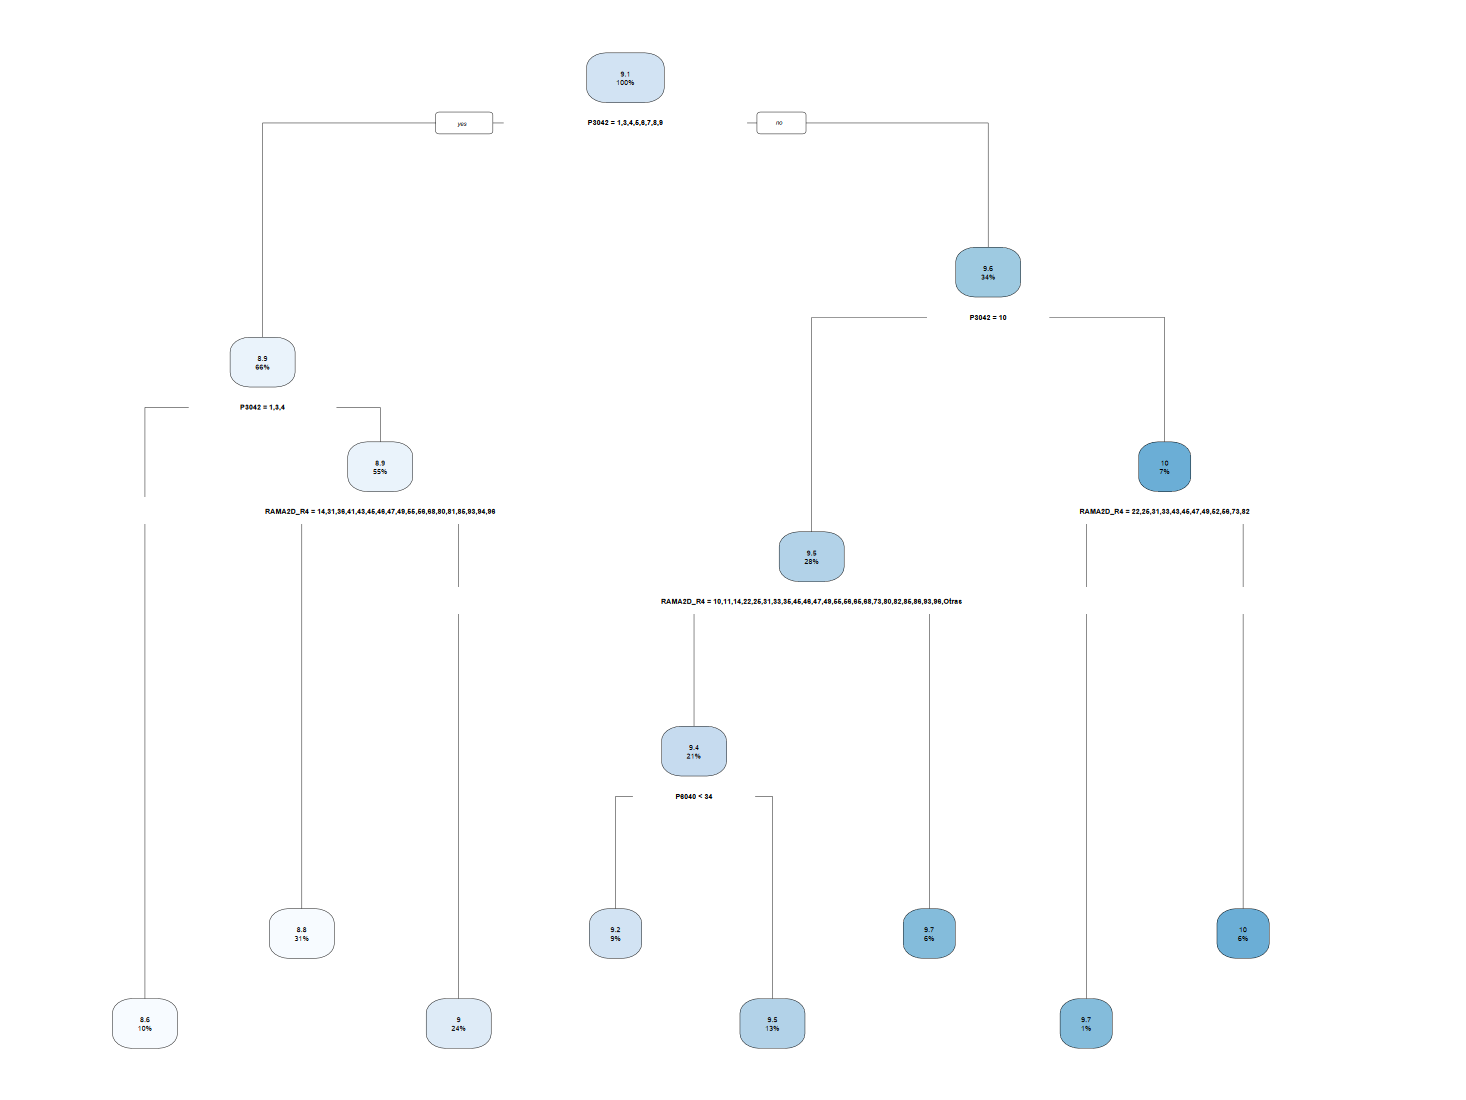

In [17]:
fit_prunedtree <- prune(tree.fit.basic, cp = bestcp)
rsq.rpart(fit_prunedtree)
rpart.plot(fit_prunedtree)

In [18]:
y_test<-data_test$lw
yhat_pt <- predict(fit_prunedtree, newdata = data_test)
mse_pt <- summary(lm((y_test - yhat_pt)^2 ~ 1))$coef[1:2]
r2_pt <- 1 - mse_pt[1] / var(y_test)
cat("R2:",round(r2_pt,2),
" | MSE:",round(mse_pt[1],2), "\n")

R2: 0.42  | MSE: 0.2 


## Bagging

In [19]:
p <- length(all.vars(basic)) - 1

In [20]:

fit_bagg <- randomForest(basic, ntree = 2000, nodesize = 20,mtry=p, data = data_train)
fit_bagg
yhat_bagg<-predict(fit_bagg,newdata = data_test)
mse_bagg <- summary(lm((y_test - yhat_bagg)^2 ~ 1))$coef[1:2]
r2_bagg<- 1 - mse_bagg[1] / var(y_test)
cat("R2:",round(r2_bagg,2),
" | MSE:",round(mse_bagg[1],2), "\n")

R2: 0.43  | MSE: 0.2 


## Random forest sin Bagging

In [21]:
fit_rf <- randomForest(basic,ntree = 2000, nodesize = 20, data = data_train)
fit_rf
yhat_rf<-predict(fit_rf,newdata = data_test)
mse_rf<- summary(lm((y_test - yhat_rf)^2 ~ 1))$coef[1:2]
r2_rf<- 1 - mse_rf[1] / var(y_test)
cat("R2:",round(r2_rf,2),
" | MSE:",round(mse_rf[1],2), "\n")

R2: 0.42  | MSE: 0.2 


# Ejercicio

Use los datos del notebook de [inferencia causal](https://colab.research.google.com/github/andvarga-eco/econometrics_ml/blob/main/notebooks/wgap_informal_causal.ipynb). El objetivo es construir un modelo de predicción/clasificación de informalidad. Use los siguientes modelos para hacer la clasificación

1. Regresión lineal
2. Logit
3. Árbol de decisión
4. Bosque aleatorio

Para cada uno de ellos construya la matriz de confusión, y las gráficas ROC y AUC. ¿Cuál de los modelos tiene mejor desempeño predictivo?
